# Image Classification using CNN

At the end of this tutorial, you would get familiarized with

*   Applying deeper convolutional architectures such as VGG
*   Use different optimizers and tuning hyperparameters
*   Application of these methods to medical images
*   Regularization methods on networks
*   Data augmentation

**Remember this is a graded exercise.**

*   For every plot, make sure you provide appropriate titles, axis labels, legends, wherever applicable.
*   Create reusable functions where ever possible, so that the code could be reused at different places.
*   Add sufficient comments and explanations wherever necessary.
*   **Once you have the code completed, use GPU to train model faster.**

---

## Group
- Ecem Onat Cakmak  
- Michael Eskander  
- Pablo Longán Gasol

# **Working with a new dataset: Colorectal-histology**
The dataset consists of a collection of textures in histological images of human colorectal cancer. It contains 5000 histological RGB images of 150 * 150 px. These images can be classified into 8 categories: tumor, stroma, complex, lympho, debris, mucosa, adipose, empty.

This dataset is part of Tensorflow datasets. **TensorFlow Datasets (TFDS)** is a library provided by TensorFlow that simplifies the process of accessing and using various datasets. It provides a collection of ready-to-use datasets with standardized APIs, making it easy to incorporate them into TensorFlow workflows.


More info regarding the dataset: https://zenodo.org/record/53169#.XGZemKwzbmG
On TFDS: https://www.tensorflow.org/datasets/catalog/colorectal_histology

Load the dataset:


*   From tfds, load the "colorectal_histology" dataset. Set with_info = True so you get information such as class labels. Split should be "train". Since you are extracting the dataset info, the command will return a tuple (ds, ds_info) containing dataset information (version, features, splits, num_examples,...). Make sure to split the results into 2 objects: "dataset" and "info".




In [ ]:
#%pip install matplotlib seaborn scikit-learn
!pip install -q tensorflow-datasets importlib_resources

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 31.2 MB/s  0:00:00 eta 0:00:01
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 34.6 MB/s  0:00:00 eta 0:00:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 32.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 38.9 MB/s  0:00:00eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 33.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.5/20.5 MB 35.8 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15/15 [scikit-learn] [scikit-learn]

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


### Execution environment: 
Initial experiments were run on Google Colab. After reaching its free GPU usage limit, the notebook was rerun locally on an Apple M4 MacBook Air with 24 GB of unified memory. TensorFlow 2.18.1 and the tensorflow-metal 1.2.0 plugin were used to enable GPU acceleration. The saved results correspond to this local run. The installation cell is specific to the macOS environment and can be skipped when using Colab.

In [ ]:
#%pip install "tensorflow==2.18.1" "tensorflow-metal==1.2.0"

  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-1-py2.py3-none-macosx_11_0_arm64.whl.metadata (5.2 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached setuptools-84.2.1-py3-none-any.whl.metadata (6.6 kB)
  Using cached rich-15.0.0-py3-none-any.whl.metadata (18 kB)
  Using cached namex-0.1.0-py3-none-any.whl.metadata (322 bytes)
  Using cached markdown_it_py-4.2.0-py3-none-any.whl.metadata (7.4 kB)
  Using cached mdurl-0.1.2-py3-none-any.whl.metadata (1.6 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 239.6/239.6 MB 37.8 MB/s  0:00:06m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 39.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 36.6 MB/s  0:00:00e

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import confusion_matrix

dataset, info = tfds.load("colorectal_histology", split="train", with_info=True)

2026-11-04 22:54:17.621010: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M4
2026-11-04 22:54:17.621045: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 24.00 GB
2026-11-04 22:54:17.621051: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 8.88 GB
I0000 00:00:1793829257.621087 11573112 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1793829257.621127 11573112 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In this section, the code for visualizing labels information, and other data exploration and preparation is provided. This code is:
*   Shuffling the dataset
*   Splitting into train, test and validation. 20% for testing, 10% for validation and the rest for training.

Run this code and ensure you understand the process.

In [2]:
# Set a seed value for replicability
import tensorflow as tf
tf.random.set_seed(1234) #you can put another seed
# Labels
class_labels = info.features['label'].names
print("Class labels:", class_labels)
# Size
dataset_size = tf.data.experimental.cardinality(dataset).numpy()
print(dataset_size)
# Split the dataset into train, test, and validation
test_dataset = dataset.take(int(0.2*dataset_size))
validation_dataset = dataset.skip(int(0.2*dataset_size)).take(int(0.1*dataset_size))
train_dataset = dataset.skip(int(0.3*dataset_size))
# Shuffle the train dataset
train_dataset = train_dataset.shuffle(buffer_size=100, seed=1234)

# Print the size of each set
print("Train set size:", tf.data.experimental.cardinality(train_dataset).numpy())
print("Test set size:", tf.data.experimental.cardinality(test_dataset).numpy())
print("Validation set size:", tf.data.experimental.cardinality(validation_dataset).numpy())


Class labels: ['tumor', 'stroma', 'complex', 'lympho', 'debris', 'mucosa', 'adipose', 'empty']
5000
Train set size: 3500
Test set size: 1000
Validation set size: 500


Now, split each set into x (image) and y (label). You can leverage this function:
````
def split_features_labels(example):
    x = example['image']
    y = example['label']
    return x, y
````

In [3]:
def split_features_labels(example):
    return example['image'], example['label']

def to_numpy(ds):
    """Convert a tf.data dataset into numpy arrays (x, y)."""
    x, y = zip(*tfds.as_numpy(ds.map(split_features_labels)))
    return np.stack(x), np.array(y)

x_train, y_train = to_numpy(train_dataset)
x_val, y_val = to_numpy(validation_dataset)
x_test, y_test = to_numpy(test_dataset)

2026-11-04 22:54:29.911249: I tensorflow/core/kernels/data/tf_record_dataset_op.cc:376] The default buffer size is 262144, which is overridden by the user specified `buffer_size` of 8388608
2026-11-04 22:54:30.317257: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
2026-11-04 22:54:30.386117: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Print the shape of a couple if images in the dataset.

In [4]:
for i in range(3):
    print("Image", i, "shape:", x_train[i].shape)

Image 0 shape: (150, 150, 3)
Image 1 shape: (150, 150, 3)
Image 2 shape: (150, 150, 3)


Get the observations distribution per class from the **training** set (number of images per class in this set). Use the *class_labels* object when printing your results.

In [5]:
counts = np.bincount(y_train, minlength=len(class_labels))
for name, n in zip(class_labels, counts):
    print(f"{name}: {n}")

tumor: 426
stroma: 441
complex: 436
lympho: 437
debris: 459
mucosa: 435
adipose: 422
empty: 444


Your next task is to visualize and prepare the data for the modelling:

*   Visualize the images in the dataset. Create a 5 x 8 plot showing 5 random samples from each class.
*   Convert the labels to one-hot encoded form.
*   Normalize the images.

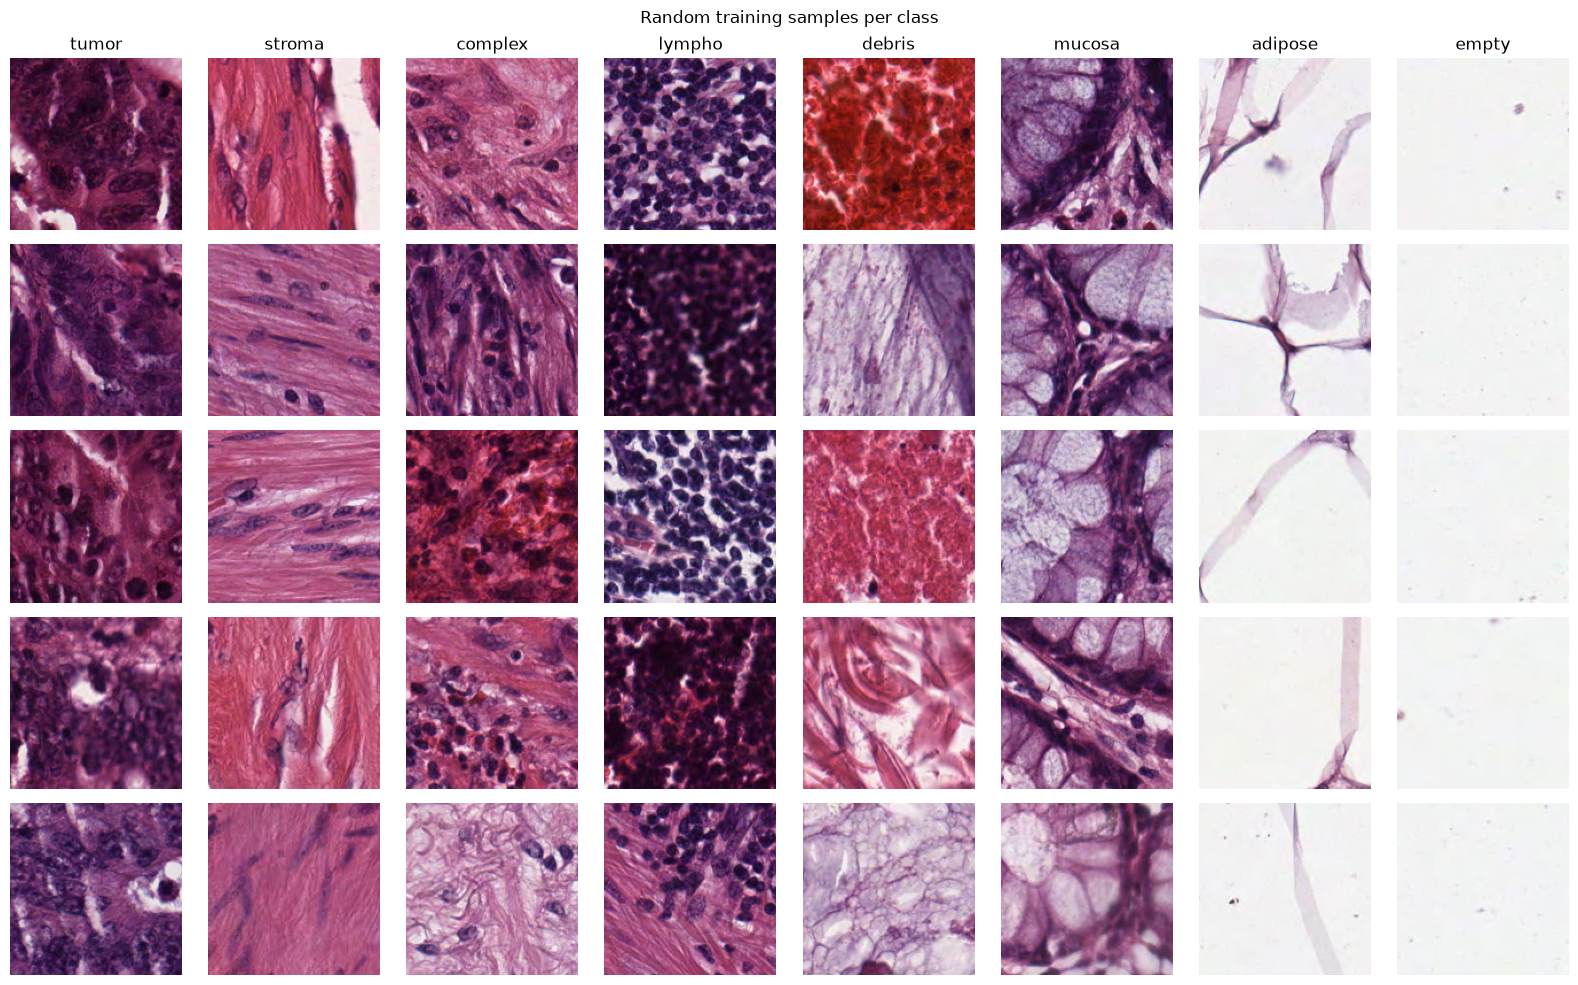

In [6]:
# 5 x 8 grid: 5 random samples (rows) for each class (columns)
fig, axes = plt.subplots(5, 8, figsize=(16, 10))
for c, name in enumerate(class_labels):
    idx = np.random.choice(np.where(y_train == c)[0], 5, replace=False)
    for r, i in enumerate(idx):
        axes[r, c].imshow(x_train[i])
        axes[r, c].axis("off")
    axes[0, c].set_title(name)
plt.suptitle("Random training samples per class")
plt.tight_layout()
plt.show()

# One-hot encode the labels
n_classes = len(class_labels)
y_train, y_val, y_test = [to_categorical(y, n_classes) for y in (y_train, y_val, y_test)]

# Normalize the images to [0, 1]
x_train, x_val, x_test = [x.astype("float32") / 255.0 for x in (x_train, x_val, x_test)]

**Data Augmentation**

Data augmentation is a technique used to artificially increase the diversity and size of the **training** dataset by applying various transformations to the original data. The goal is to expose the model to different variations of the same data, which helps improve the model's ability to generalize. Common data augmentation techniques include rotations, horizontal and vertical flips, zooms, etc.

Get to know better the transformations available [here](https://www.tensorflow.org/api_docs/python/tf/keras/preprocessing/image/ImageDataGenerator)

 How data augmentation works is that during each epoch, the generator will apply random transformations to the images on-the-fly, providing augmented data to the model for training.

 For this exercise, use **ImageDataGenerator** from tensorflow. Set the rotation angle degrees to 20, 0.1 horizontal and vertical shift, randomly flip images horizontally and use fill_mode="nearest". Apply it to the training set

In [7]:
train_datagen = ImageDataGenerator(rotation_range=20,
                                   width_shift_range=0.1,
                                   height_shift_range=0.1,
                                   horizontal_flip=True,
                                   fill_mode="nearest")
augmented_data = train_datagen.flow(x_train, y_train, batch_size=32)

Create an ImageDtaGenerator for your test and validation data. This one does not need to set any parameter when you create the generator. Use .flow() with your x and y values as well as your batch_size and shuffle parameter set to False

In [8]:
eval_datagen = ImageDataGenerator()
val_data = eval_datagen.flow(x_val, y_val, batch_size=32, shuffle=False)
test_data = eval_datagen.flow(x_test, y_test, batch_size=32, shuffle=False)

Provided the description of what data augmentation is, is this a modification that can be done to all sets (train, test and validation) or is this specifically for training? Why?

**Solution**

*Data augmentation is only for the training set. Its purpose is to add variety so the model generalizes better. Validation and test sets must stay unmodified data so that the metrics reflect true performance and are comparable and reproducible across models.*

...

## Define the following model

**For the convolutional front-end, start with a single convolutional layer with a small filter size (3,3) and a modest number of filters (32) followed by a max pooling layer. Use the input as (150,150,3). The filter maps can then be flattened to provide features to the classifier. Use a dense layer with 100 units before the classification layer (which is also a dense layer with softmax activation).*

In [9]:
model = keras.Sequential([
    layers.Input(shape=(150, 150, 3)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Flatten(),
    layers.Dense(100, activation="relu"),
    layers.Dense(len(class_labels), activation="softmax"),
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 175232)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │    17,523,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           808 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,525,004 (66.85 MB)

 Trainable params: 17,525,004 (66.85 MB)

 Non-trainable params: 0 (0.00 B)

*   Compile the model using categorical_crossentropy loss, SGD optimizer with a learning rate of 0.0001 and use 'accuracy' as the metric.
*   Use the above defined model to train over this dataset and train the model for 50 epochs with a batch size of 32.
*   Include the validation set in the fit function
*   Use the augmented_data

In [10]:
model.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

history = model.fit(
    augmented_data,
    epochs=50,
    validation_data=val_data,
)

Epoch 1/50


2026-11-04 22:54:58.999409: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


110/110 ━━━━━━━━━━━━━━━━━━━━ 7s 46ms/step - accuracy: 0.1369 - loss: 2.0245 - val_accuracy: 0.1280 - val_loss: 1.9991
Epoch 2/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - accuracy: 0.1586 - loss: 1.9595 - val_accuracy: 0.1580 - val_loss: 1.9369
Epoch 3/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - accuracy: 0.2069 - loss: 1.8991 - val_accuracy: 0.2160 - val_loss: 1.8909
Epoch 4/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 6s 53ms/step - accuracy: 0.2271 - loss: 1.8491 - val_accuracy: 0.2240 - val_loss: 1.8352
Epoch 5/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 6s 53ms/step - accuracy: 0.2560 - loss: 1.8012 - val_accuracy: 0.2200 - val_loss: 1.7911
Epoch 6/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step - accuracy: 0.2637 - loss: 1.7608 - val_accuracy: 0.3020 - val_loss: 1.7565
Epoch 7/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 5s 42ms/step - accuracy: 0.2763 - loss: 1.7198 - val_accuracy: 0.3080 - val_loss: 1.7018
Epoch 8/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - accuracy: 0.3000 - loss: 1.6844 - val_accuracy: 0.314

* Plot the train and validation loss by epoch
* Plot the train and validation accuracy by epoch

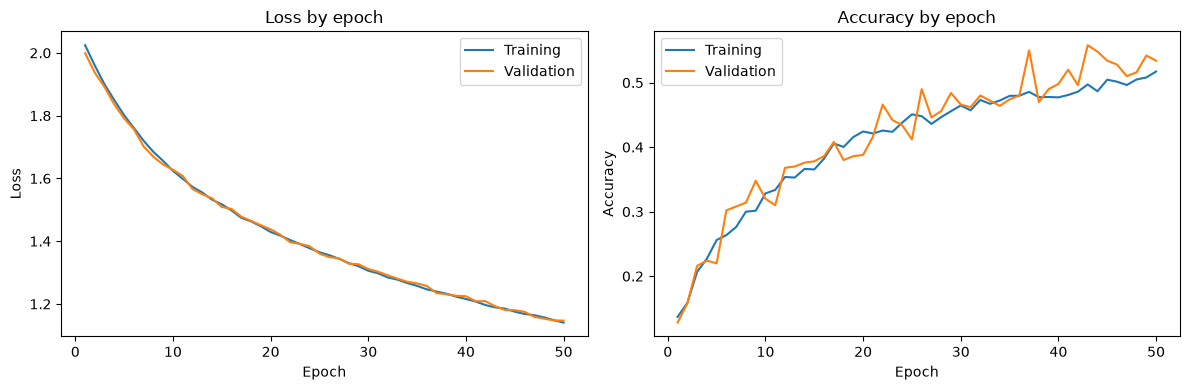

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epochs = range(1, len(history.history["loss"]) + 1)

axes[0].plot(epochs, history.history["loss"], label="Training")
axes[0].plot(epochs, history.history["val_loss"], label="Validation")
axes[0].set(title="Loss by epoch", xlabel="Epoch", ylabel="Loss")
axes[0].legend()

axes[1].plot(epochs, history.history["accuracy"], label="Training")
axes[1].plot(epochs, history.history["val_accuracy"], label="Validation")
axes[1].set(title="Accuracy by epoch", xlabel="Epoch", ylabel="Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

*   Use predict function to predict the output for the test split
*   Plot the confusion matrix for the new model and comment on the class confusions.


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


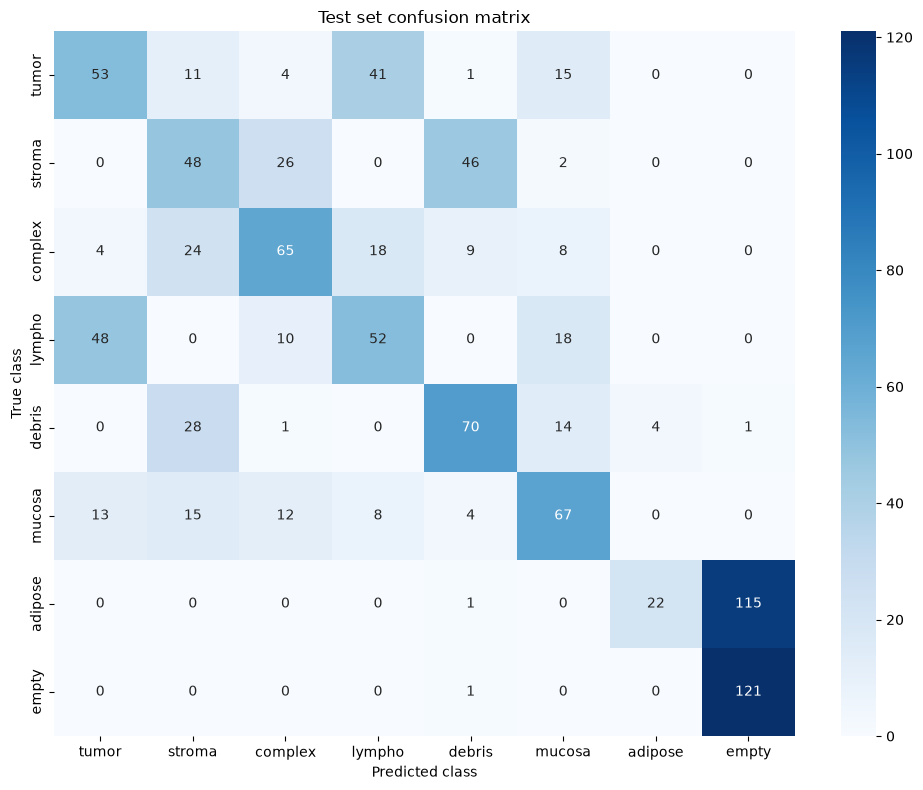

In [12]:
# test_data was created with shuffle=False, preserving label order.
test_data.reset()
probabilities = model.predict(test_data)
y_pred = np.argmax(probabilities, axis=1)
y_true = np.argmax(y_test, axis=1)

cm = confusion_matrix(
    y_true, y_pred, labels=np.arange(len(class_labels))
)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels,
)
plt.title("Test set confusion matrix")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.tight_layout()
plt.show()

**Solution**

The model correctly classified 498 of the 1,000 test images, giving a test accuracy of **49.8%**. The empty class had the highest recall, with 121 of 122 images correctly identified. However, 115 of 138 adipose images were also predicted as empty, while only 22 were correctly classified as adipose. This shows that the model struggles to distinguish these two classes, even though it recognizes most actual empty images.

Other frequent errors were between tumor and lympho: 41 tumor images were predicted as lympho, and 48 lympho images were predicted as tumor. Stroma and debris were also confused in both directions, with 46 stroma images classified as debris and 28 debris images classified as stroma. These errors may reflect similarities in tissue appearance, but the confusion matrix alone cannot establish their cause.


Print the test accuracy for the trained model.

In [13]:
test_loss, test_accuracy = model.evaluate(test_data)
print(f"Test accuracy: {test_accuracy:.2%}")

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.4980 - loss: 1.1445
Test accuracy: 49.80%


# Hyperparameter tuning

In this section, we emphasize on the importance of hyperparameter choices. There are several aspect of the algorithm that have great impact on the performance of the final model:

*   **Optimizers:** We have been using mostly Stochastic Gradient Descent (SGD) and Adam. There is also: RMSprop, Adagrad, Adadelta and more.
*   **Regularizers:** Some techniques are L1, L2, Dropout, Batch normalization and Early Stopping.
*   **Learning rate:** Besides having a specific value, we can have an adaptive learning rate (for example ReduceLROnPlateau or exponentially decresing).
*   **Batch size:** Recommended to use power of 2 values and adjust to computational power. Besides memory usage, this can affect stability of the training process.

On this section we will focus on finding a good **learning rate**. For this:

*   Use the complete VGG model with the original image shape. Train for 15 epochs. Make sure to use the validation data during the training process
*   Use SGD varying the learning rate to these values: [0.00001,0.0001,0.01]. You can use a for loop to train them and store the validation loss and accuracy
*   Plot the results of loss and accuracy for the different learning rates into one plot for each metric (loss and accuracy).



In [14]:
from keras.backend import clear_session
clear_session()

In [15]:
def build_vgg():
    model = keras.Sequential([
        layers.Input(shape=(150, 150, 3))
    ])

    for filters in [64, 128, 256]:
        model.add(layers.Conv2D(
            filters, (3, 3), activation="relu", padding="same"
        ))
        model.add(layers.Conv2D(
            filters, (3, 3), activation="relu", padding="same"
        ))
        model.add(layers.MaxPooling2D(pool_size=(2, 2)))

    model.add(layers.Flatten())
    model.add(layers.Dense(128, activation="relu"))
    model.add(layers.Dense(len(class_labels), activation="softmax"))
    return model

In [16]:
# Reusable helper functions

def plot_history(history, title=""):
    """Plot training vs validation loss and accuracy by epoch."""
    h = history.history
    epochs = range(1, len(h["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(epochs, h["loss"], label="Training")
    axes[0].plot(epochs, h["val_loss"], label="Validation")
    axes[0].set(title=f"{title} - Loss by epoch", xlabel="Epoch", ylabel="Loss")
    axes[0].legend()

    axes[1].plot(epochs, h["accuracy"], label="Training")
    axes[1].plot(epochs, h["val_accuracy"], label="Validation")
    axes[1].set(title=f"{title} - Accuracy by epoch", xlabel="Epoch", ylabel="Accuracy")
    axes[1].legend()

    plt.tight_layout()
    plt.show()


def plot_confusion_matrix(model, data, y_onehot, title="Test set confusion matrix"):
    """Predict on a non-shuffled generator and plot the confusion matrix."""
    data.reset()                                  # start from the first batch -> same order as y_onehot
    y_pred = np.argmax(model.predict(data), axis=1)
    y_true = np.argmax(y_onehot, axis=1)
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(class_labels)))

    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_labels, yticklabels=class_labels)
    plt.title(title)
    plt.xlabel("Predicted class")
    plt.ylabel("True class")
    plt.tight_layout()
    plt.show()
    return cm

In [17]:
learning_rates = [0.00001, 0.0001, 0.01]
lr_histories = {}

for lr in learning_rates:
    keras.backend.clear_session()
    keras.utils.set_random_seed(1234)

    model_vgg = build_vgg()
    model_vgg.compile(
        optimizer=keras.optimizers.SGD(learning_rate=lr),
        loss="categorical_crossentropy",
        metrics=["accuracy"],
    )

    # Create a fresh generator for each experiment.
    train_data_lr = train_datagen.flow(
        x_train, y_train, batch_size=32, shuffle=True, seed=1234
    )
    val_data.reset()

    print(f"\nTraining with learning rate = {lr}")
    result = model_vgg.fit(
        train_data_lr,
        epochs=15,
        validation_data=val_data,
    )
    lr_histories[lr] = result.history



Training with learning rate = 1e-05
Epoch 1/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 31s 268ms/step - accuracy: 0.1311 - loss: 2.0804 - val_accuracy: 0.1040 - val_loss: 2.0829
Epoch 2/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 30s 278ms/step - accuracy: 0.1280 - loss: 2.0802 - val_accuracy: 0.1060 - val_loss: 2.0826
Epoch 3/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 31s 284ms/step - accuracy: 0.1363 - loss: 2.0798 - val_accuracy: 0.1060 - val_loss: 2.0823
Epoch 4/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 33s 299ms/step - accuracy: 0.1340 - loss: 2.0792 - val_accuracy: 0.1060 - val_loss: 2.0819
Epoch 5/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 35s 316ms/step - accuracy: 0.1334 - loss: 2.0792 - val_accuracy: 0.1040 - val_loss: 2.0817
Epoch 6/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 36s 330ms/step - accuracy: 0.1346 - loss: 2.0788 - val_accuracy: 0.1040 - val_loss: 2.0814
Epoch 7/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 37s 335ms/step - accuracy: 0.1351 - loss: 2.0784 - val_accuracy: 0.1020 - val_loss: 2.0811
Epoch 8/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 39s 35

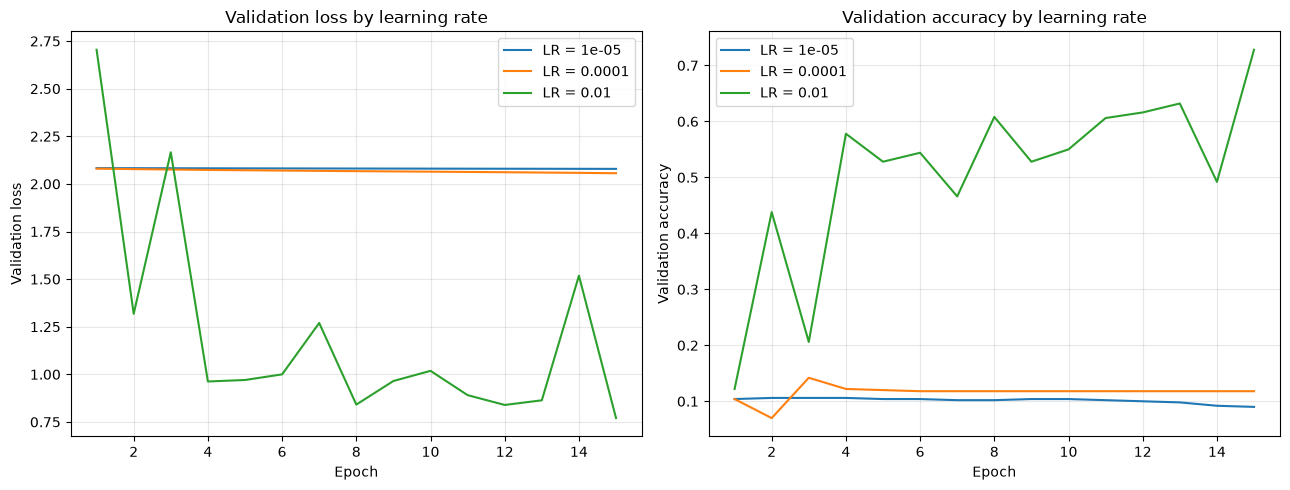

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for lr, metrics in lr_histories.items():
    epochs = range(1, len(metrics["val_loss"]) + 1)

    axes[0].plot(epochs, metrics["val_loss"], label=f"LR = {lr:g}")
    axes[1].plot(epochs, metrics["val_accuracy"], label=f"LR = {lr:g}")

axes[0].set(
    title="Validation loss by learning rate",
    xlabel="Epoch",
    ylabel="Validation loss",
)
axes[1].set(
    title="Validation accuracy by learning rate",
    xlabel="Epoch",
    ylabel="Validation accuracy",
)

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Comment on your results. Which one is the best learning rate on this case?

**Solution**

The best learning rate among the tested values was **0.01**. After 15 epochs, it achieved **72.8% validation accuracy** and a validation loss of **0.7704**, which were the best validation results in the learning-rate comparison. Its curves fluctuated considerably, but the overall improvement was much greater than with the smaller learning rates.

With **0.00001**, final validation accuracy was only **9.0%**, and validation loss remained at **2.0790**, approximately the cross-entropy of uniform predictions over eight classes. With **0.0001**, final validation accuracy was **11.8%** and validation loss was **2.0562**. These results indicate insufficient learning within 15 epochs. Therefore, 0.01 is the preferred learning rate for this architecture and training budget; this experiment does not establish that it is optimal for every training duration or optimizer.


## Defining Deeper Architectures: VGG Models and Dropout layer as Regularization

We add regularization to prevent overfitting, where a model performs well on the training data but poorly on unseen data. These techniques help improve the generalization of neural networks on neural networks field, there are different ways of adding regularization, some areL

1. **L1 and L2 Regularization (Weight Decay):** These methods modify the loss function, adding coefficient penalization.
2. **Dropout:** Dropout randomly sets a fraction of the neurons to zero during each forward and backward pass. This helps prevent co-adaptation of neurons and encourages the network to learn more robust features.
3. **Early Stopping:** Early stopping involves monitoring the validation error during training and stopping the training process when the validation error starts increasing.
4. **Data Augmentation:** As seen before, data augmentation involves applying random transformations to the training data, increasing the diversity of the data the model is trained on.


We are going to explore Dropout layer. Your tasks here are:
*   Define a deeper model architecture with dropout layers for the dataset and train the new model for 50 epochs with a batch size of 32.
*   Make sure to use the data augmented for training
*   Use the validation set as part of the training process

Your network architecture:
* Stack two convolutional layers with 32 filters, each of 3 x 3.
* Use a max pooling layer and next flatten the output of the previous layer and
* Flatten the output
* Add a dense layer with 128 units before the classification layer.
* Add a dropout layer with a 25% rate
* Have the final classification layer with the appropriate parameters for this task.
For all the layers, use ReLU activation function. Use same padding for the layers to ensure that the height and width of each layer output matches the input

In [19]:
from keras.backend import clear_session
clear_session()

In [20]:
#solution
# Deeper model: two stacked 3x3 conv layers (32 filters) + max pooling,
# then a dense classifier regularized with Dropout(0.25).
model_dropout = keras.Sequential([
    layers.Input(shape=(150, 150, 3)),                                     # 150x150x3
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),          # 150x150x32
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),          # 150x150x32
    layers.MaxPooling2D(pool_size=(2, 2)),                                 # 75x75x32
    layers.Flatten(),                                                      # 180000
    layers.Dense(128, activation="relu"),                                  # 128
    layers.Dropout(0.25),                       # randomly zeroes 25% of the 128 units (training only)
    layers.Dense(len(class_labels), activation="softmax"),                 # 8 class probabilities
], name="cnn_dropout")

model_dropout.summary()

Model: "cnn_dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 150, 150, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 180000)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    23,040,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,051,304 (87.93 MB)

 Trainable params: 23,051,304 (87.93 MB)

 Non-trainable params: 0 (0.00 B)

*   Compile the model using categorical_crossentropy loss, SGD optimizer and use 'accuracy' as the metric. Set the SGD parameter to 0.0001
*   Use the above defined model to train over the augmented dataset and train the model for 50 epochs with a batch size of 32.
*   Include the validation set in the fit function
*   Plot loss and accuracy for train and validation
*   Use the augmented_data


Epoch 1/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 6s 53ms/step - accuracy: 0.1343 - loss: 2.0362 - val_accuracy: 0.1240 - val_loss: 2.0126
Epoch 2/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - accuracy: 0.1609 - loss: 1.9892 - val_accuracy: 0.1580 - val_loss: 1.9717
Epoch 3/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 6s 50ms/step - accuracy: 0.1897 - loss: 1.9492 - val_accuracy: 0.1860 - val_loss: 1.9295
Epoch 4/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - accuracy: 0.2049 - loss: 1.9076 - val_accuracy: 0.1900 - val_loss: 1.8874
Epoch 5/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 5s 49ms/step - accuracy: 0.2191 - loss: 1.8659 - val_accuracy: 0.2300 - val_loss: 1.8391
Epoch 6/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 6s 53ms/step - accuracy: 0.2483 - loss: 1.8195 - val_accuracy: 0.2340 - val_loss: 1.7949
Epoch 7/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 6s 52ms/step - accuracy: 0.2520 - loss: 1.7776 - val_accuracy: 0.2460 - val_loss: 1.7526
Epoch 8/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 6s 53ms/step - accuracy: 0.2620 - loss: 1.7373 - val_accu

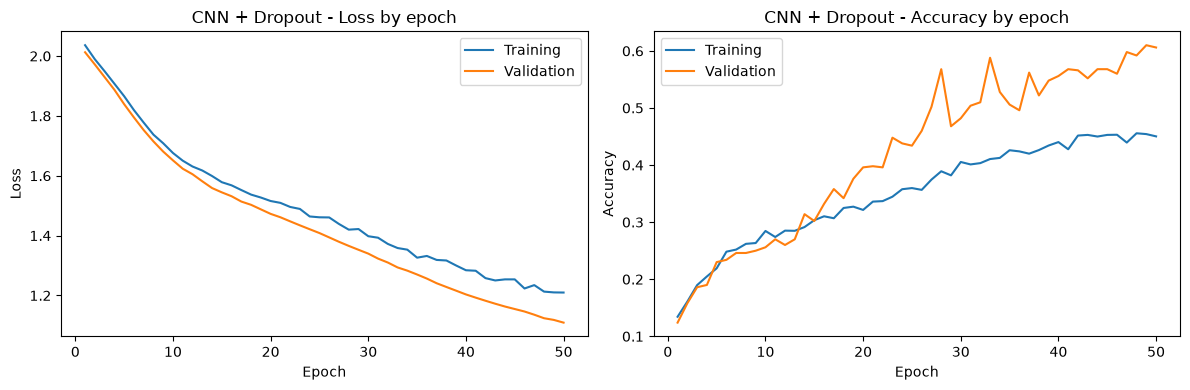

In [21]:
#solution
# Reusable plotting function (it can also be used for the later VGG and optimizer models)
def plot_history(history, title=""):
    """Plot training vs validation loss and accuracy by epoch."""
    h = history.history
    epochs = range(1, len(h["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(epochs, h["loss"], label="Training")
    axes[0].plot(epochs, h["val_loss"], label="Validation")
    axes[0].set(title=f"{title} - Loss by epoch", xlabel="Epoch", ylabel="Loss")
    axes[0].legend()

    axes[1].plot(epochs, h["accuracy"], label="Training")
    axes[1].plot(epochs, h["val_accuracy"], label="Validation")
    axes[1].set(title=f"{title} - Accuracy by epoch", xlabel="Epoch", ylabel="Accuracy")
    axes[1].legend()

    plt.tight_layout()
    plt.show()


model_dropout.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

# augmented_data was created with batch_size=32, so the batch size comes from the generator
# (do not pass batch_size to fit() when the input is a generator).
val_data.reset()
history_dropout = model_dropout.fit(
    augmented_data,
    epochs=50,
    validation_data=val_data,
)

plot_history(history_dropout, title="CNN + Dropout")

*   Use predict function to predict the output for the test split
*   Plot the confusion matrix for the new model and comment on the class confusions.


32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step


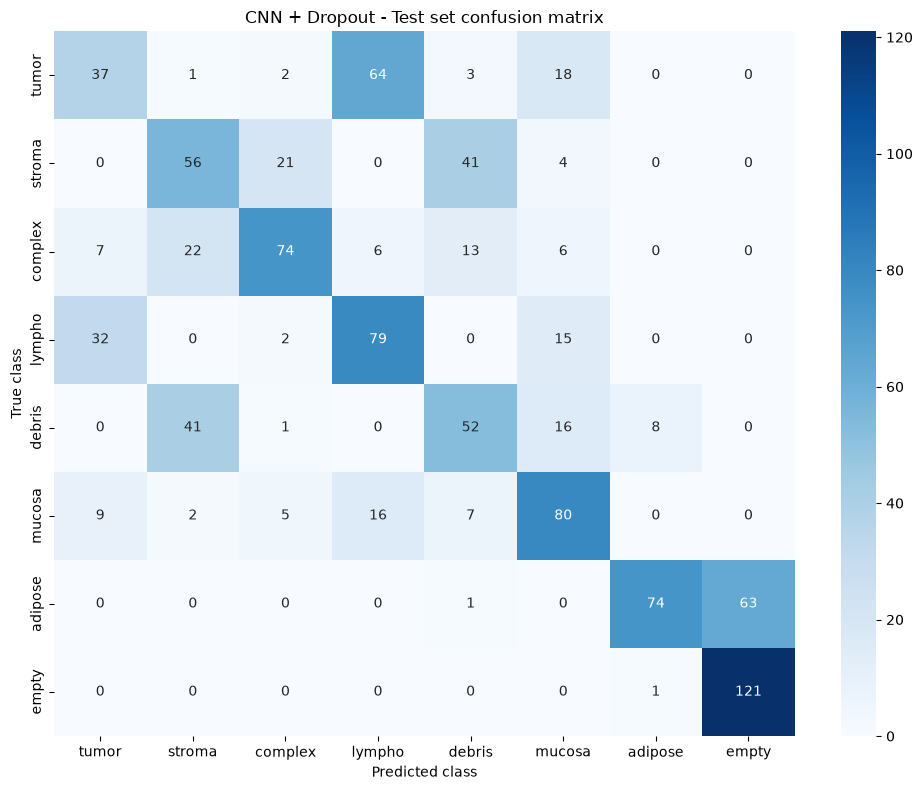

In [22]:
#solution
# Reusable confusion-matrix function
def plot_confusion_matrix(model, data, y_onehot, title="Test set confusion matrix"):
    """Predict on a non-shuffled generator and plot the confusion matrix."""
    data.reset()                                  # start from the first batch -> same order as y_onehot
    y_pred = np.argmax(model.predict(data), axis=1)
    y_true = np.argmax(y_onehot, axis=1)
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(class_labels)))

    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_labels, yticklabels=class_labels)
    plt.title(title)
    plt.xlabel("Predicted class")
    plt.ylabel("True class")
    plt.tight_layout()
    plt.show()
    return cm


cm_dropout = plot_confusion_matrix(model_dropout, test_data, y_test,
                                   title="CNN + Dropout - Test set confusion matrix")

*    Print the test accuracy for the trained model.

**Solution — confusion matrix and model comparison**

The deeper CNN with dropout correctly classified **573 of 1,000 test images (57.3%)**, compared with **49.8%** for the first CNN, an improvement of **7.5 percentage points**. Adipose classification improved from 22 to 74 correct predictions, although 63 adipose images were still classified as empty. Lympho and mucosa also improved, with 79 and 80 correct predictions, respectively.

Some confusions remained substantial. The model classified 64 tumor images as lympho, while only 37 tumor images were correctly identified. Stroma and debris were confused in both directions, with 41 errors in each direction. Thus, the improvement was not uniform across classes.

Validation accuracy at the final epoch was **60.6%**, above the reported training accuracy. This can occur because training uses random augmentation and active dropout, whereas validation uses neither. The results do not show a clear pattern of overfitting. Since both the architecture and dropout changed relative to the first model, the improvement cannot be attributed to dropout alone.


In [23]:
#solution
test_data.reset()
test_loss_dropout, test_accuracy_dropout = model_dropout.evaluate(test_data)
print(f"Test accuracy (CNN + Dropout): {test_accuracy_dropout:.2%}")
print(f"Test accuracy (first model):   {test_accuracy:.2%}")

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5730 - loss: 1.1158
Test accuracy (CNN + Dropout): 57.30%
Test accuracy (first model):   49.80%


##Complete VGG architecture and early stopping.

For this exercise, you are going to:


1.   Model full VGG architecture
  **For the VGG architecture:** Stack two convolutional layers with 64 filters, each of 3 x 3 followed by max pooling layer. Stack two more convolutional layers with 128 filters, each of 3 x 3, followed by max pooling, follwed by two more convolutional layers with 256 filters, each of 3 x 3, followed by max pooling. Flatten the output of the previous layer and add a dense layer with 128 units before the classification layer. For all the layers, use ReLU activation function. Use same padding for the layers to ensure that the height and width of each layer output matches the input.

2.   Use early stopping as regulatization:
  Early stopping is a technique to prevent overfitting during training. The idea behind early stopping is to monitor the performance of the model on a validation set during training. If the performance on the validation set stops improving or starts to degrade, the training process is stopped early, hence the name "early stopping."
  There are two key parameters to set: p choosing a metric to monitor and specifying a patience value, which represents the number of epochs the training can continue without improvement on the validation set.

  Use keras.callbacks function, monitor the validation loss metric with a patience of 3. Make sure to keep the best weights (Hint: there is a parameter for this in the early stopping function). In the model fitting, specify the callback to this object that you had created

In [24]:
from keras.backend import clear_session
clear_session()

In [25]:
#solution
# 1) Full VGG architecture: 3 VGG blocks (64 -> 128 -> 256 filters).
#    We reuse build_vgg() from the learning-rate section, which already follows this specification:
#    [Conv3x3 + Conv3x3 + MaxPool] x 3 -> Flatten -> Dense(128) -> Dense(8, softmax), ReLU and same padding.
keras.utils.set_random_seed(1234)
model_vgg_es = build_vgg()
model_vgg_es.summary()

# 2) Early stopping as regularization:
#    stop when val_loss has not improved for 3 consecutive epochs
#    and roll back to the weights of the best epoch.
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1,
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 150, 150, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 150, 150, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 75, 75, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 75, 75, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 37, 37, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 37, 37, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 82944)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    10,616,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,763,400 (44.87 MB)

 Trainable params: 11,763,400 (44.87 MB)

 Non-trainable params: 0 (0.00 B)

*   Compile the model using categorical_crossentropy loss, SGD (learning rate of 0.0001) optimizer and use 'accuracy' as the metric.
*   Use the above defined model and train the model for 50 epochs with a batch size of 32.
*   Predict the output for the test split and plot the confusion matrix for the new model and comment on the class confusions.

Epoch 1/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 37s 334ms/step - accuracy: 0.1400 - loss: 2.0789 - val_accuracy: 0.1040 - val_loss: 2.0802
Epoch 2/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 36s 331ms/step - accuracy: 0.1114 - loss: 2.0760 - val_accuracy: 0.0700 - val_loss: 2.0778
Epoch 3/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 40s 367ms/step - accuracy: 0.1440 - loss: 2.0735 - val_accuracy: 0.1400 - val_loss: 2.0755
Epoch 4/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 41s 377ms/step - accuracy: 0.1443 - loss: 2.0706 - val_accuracy: 0.1220 - val_loss: 2.0735
Epoch 5/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 41s 373ms/step - accuracy: 0.1314 - loss: 2.0687 - val_accuracy: 0.1200 - val_loss: 2.0718
Epoch 6/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 40s 366ms/step - accuracy: 0.1277 - loss: 2.0667 - val_accuracy: 0.1180 - val_loss: 2.0702
Epoch 7/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 40s 366ms/step - accuracy: 0.1274 - loss: 2.0648 - val_accuracy: 0.1180 - val_loss: 2.0686
Epoch 8/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 40s 364ms/step - accuracy: 0.1269 - loss: 2

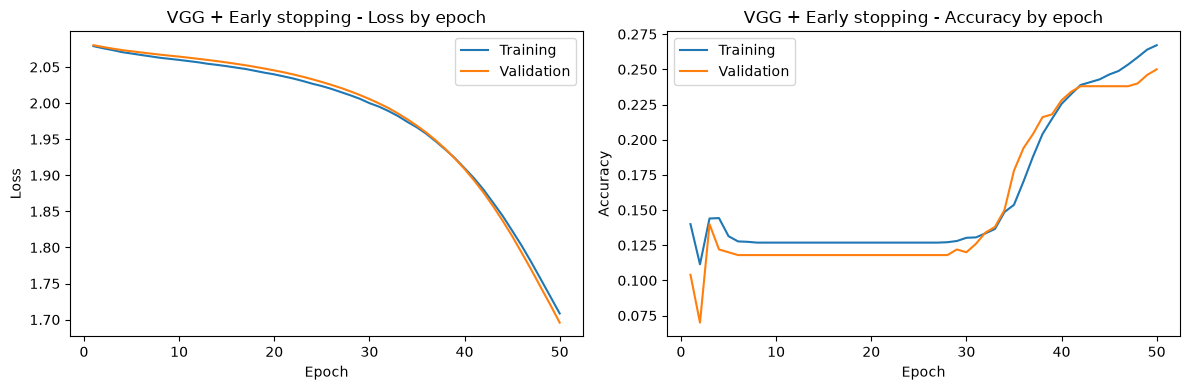

32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 89ms/step


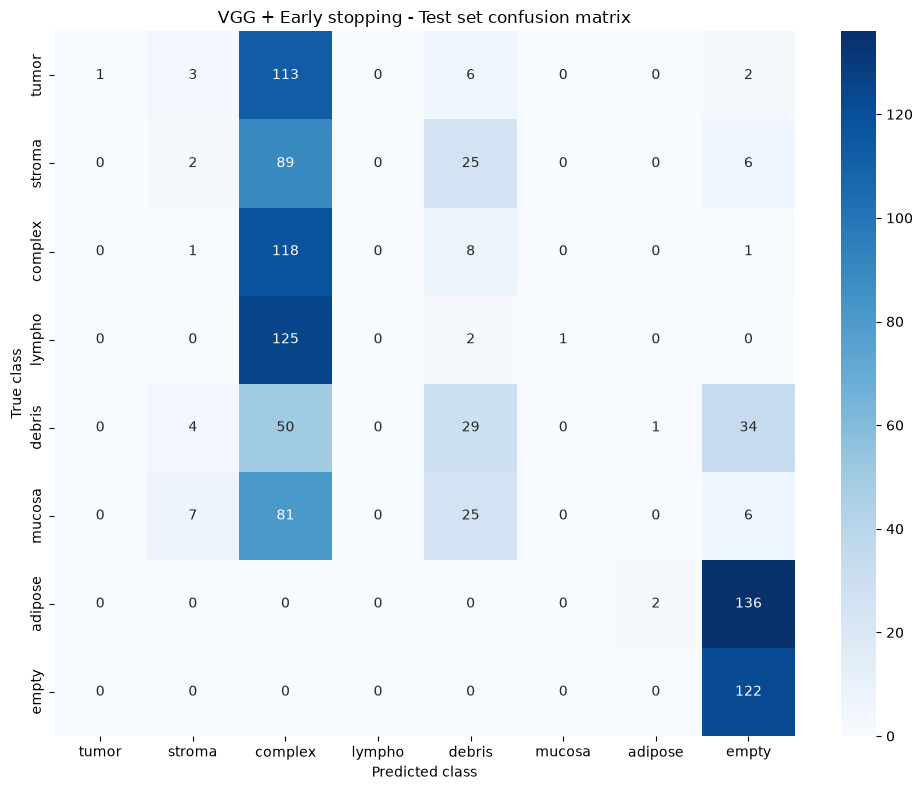

32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 83ms/step - accuracy: 0.2740 - loss: 1.6863
Test accuracy (VGG + Early stopping): 27.40%


In [26]:
#solution
model_vgg_es.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

# Batch size 32 comes from the augmented_data generator.
val_data.reset()
history_vgg_es = model_vgg_es.fit(
    augmented_data,
    epochs=50,
    validation_data=val_data,
    callbacks=[early_stopping],     # the early stopping object is passed here
)

# How many epochs were actually run, and which one was the best
n_epochs_run = len(history_vgg_es.history["loss"])
best_epoch = int(np.argmin(history_vgg_es.history["val_loss"])) + 1
print(f"Epochs run: {n_epochs_run} / 50 - best epoch (lowest val_loss): {best_epoch}")

plot_history(history_vgg_es, title="VGG + Early stopping")

# Predict on the test split and plot the confusion matrix
cm_vgg_es = plot_confusion_matrix(model_vgg_es, test_data, y_test,
                                  title="VGG + Early stopping - Test set confusion matrix")

test_data.reset()
test_loss_vgg_es, test_accuracy_vgg_es = model_vgg_es.evaluate(test_data)
print(f"Test accuracy (VGG + Early stopping): {test_accuracy_vgg_es:.2%}")

**Solution**

Early stopping did not terminate training: validation loss decreased in every epoch, so the model completed all **50 epochs**, and the callback restored the weights from **epoch 50**, the best epoch. Final validation accuracy was **25.0%**, with a validation loss of **1.6958**. Test accuracy was **27.4%**. Both training and validation performance remained low, which suggests underfitting or insufficient convergence rather than a clear pattern of overfitting.

The confusion matrix shows a strong bias toward the complex and empty classes. The model classified 113 tumor, 89 stroma, 125 lympho and 81 mucosa images as complex. It correctly identified 118 complex images and all 122 empty images, but classified 136 of 138 adipose images as empty. It never predicted lympho and made no correct mucosa predictions. The model therefore had not learned to distinguish several tissue classes reliably.

This VGG model performed worse on the test set than the first CNN (**49.8%**) and the deeper CNN with dropout (**57.3%**). In the separate learning-rate experiment, VGG with SGD at **0.01** reached **72.8% validation accuracy** after 15 epochs, compared with only 25.0% here after 50 epochs at 0.0001. These validation results show how strongly optimization settings affect this architecture. Early stopping can limit training when validation performance stops improving, but it does not make a slowly learning model converge faster.


# Understanding deep networks

*   What is the use of activation functions in network? Why is it needed?
*   We have used softmax activation function in the exercise. There are other activation functions available too. What is the difference between sigmoid activation and softmax activation?
*   What is the difference between categorical crossentropy and binary crossentropy loss?

**Solution**

- **Activation functions:** A neuron combines its inputs using weights and a bias, then applies an activation function. Nonlinear activations allow the network to learn complex relationships, such as tissue textures. Without nonlinear activations, a sequence of affine layers would collapse to a single affine transformation. We use ReLU in the hidden layers because it is simple and maintains gradients for positive inputs.

- **Sigmoid and softmax:** Sigmoid maps each output independently to a value between 0 and 1. It is commonly used for binary classification with one output, or for multilabel classification where several labels can apply to one example. Softmax converts the outputs into probabilities that sum to 1 and is appropriate when classes are mutually exclusive. Our model uses eight softmax outputs because each image has exactly one tissue label.

- **Cross-entropy losses:** Binary cross-entropy is typically used with sigmoid outputs for binary or multilabel classification. Categorical cross-entropy is typically used with softmax outputs for mutually exclusive classes and one-hot encoded labels. Sparse categorical cross-entropy supports the same mutually exclusive classification task with integer labels. In this lab, categorical cross-entropy matches our eight classes and one-hot encoded targets.


# Hyperparameter tuning - optimzers

Explore the effect of the optimizer on this data:

*   Set the learning rate to 0.0001 and now use different optimizers: RMSprop and Adam. Train for 15 epochs
*   Plot validation loss and accuracy for the different models and compare the results.



In [27]:
clear_session()


Training with optimizer = RMSprop
Epoch 1/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 31s 276ms/step - accuracy: 0.3329 - loss: 1.5468 - val_accuracy: 0.4060 - val_loss: 1.2459
Epoch 2/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 31s 285ms/step - accuracy: 0.4791 - loss: 1.1367 - val_accuracy: 0.5380 - val_loss: 0.9261
Epoch 3/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 33s 299ms/step - accuracy: 0.5414 - loss: 1.0576 - val_accuracy: 0.5700 - val_loss: 0.9706
Epoch 4/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 40s 366ms/step - accuracy: 0.5706 - loss: 1.0026 - val_accuracy: 0.5560 - val_loss: 1.0154
Epoch 5/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 44s 397ms/step - accuracy: 0.6383 - loss: 0.9157 - val_accuracy: 0.5940 - val_loss: 1.1558
Epoch 6/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 42s 379ms/step - accuracy: 0.6866 - loss: 0.8665 - val_accuracy: 0.7620 - val_loss: 0.6751
Epoch 7/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 40s 365ms/step - accuracy: 0.6783 - loss: 0.8792 - val_accuracy: 0.7680 - val_loss: 0.7038
Epoch 8/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 40s 364m

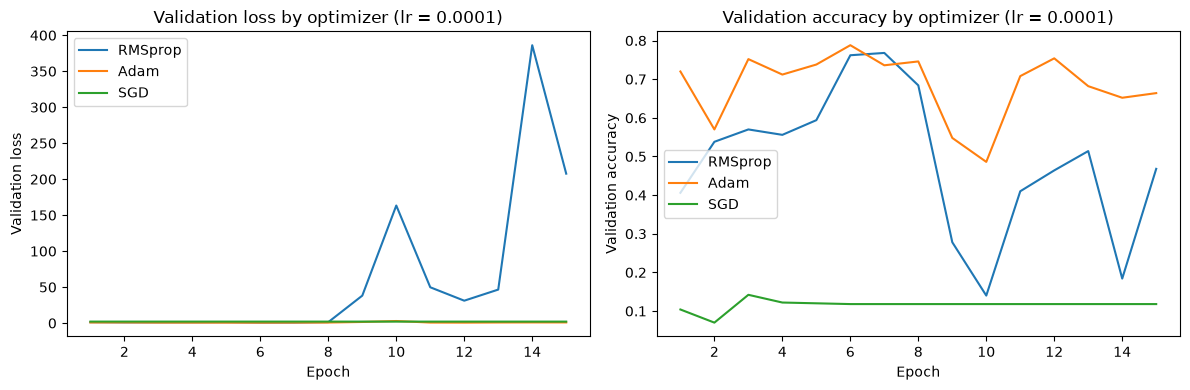

Optimizer   Final val_loss  Final val_acc  Best val_acc
RMSprop           207.6615         46.80%        76.80%
Adam                0.9203         66.40%        78.80%
SGD                 2.0562         11.80%        14.20%


In [28]:
#solution
# Same full VGG architecture and same learning rate (0.0001) for every experiment,
# so the only thing that changes is the optimizer.
optimizers_to_test = {
    "RMSprop": lambda: keras.optimizers.RMSprop(learning_rate=0.0001),
    "Adam":    lambda: keras.optimizers.Adam(learning_rate=0.0001),
}
opt_histories = {}

for name, make_optimizer in optimizers_to_test.items():
    keras.backend.clear_session()
    keras.utils.set_random_seed(1234)

    model_opt = build_vgg()
    model_opt.compile(
        optimizer=make_optimizer(),          # a new optimizer object for each model
        loss="categorical_crossentropy",
        metrics=["accuracy"],
    )

    # Fresh augmented generator for each experiment (same seed -> same augmentations)
    train_data_opt = train_datagen.flow(
        x_train, y_train, batch_size=32, shuffle=True, seed=1234
    )
    val_data.reset()

    print(f"\nTraining with optimizer = {name}")
    result = model_opt.fit(
        train_data_opt,
        epochs=15,
        validation_data=val_data,
    )
    opt_histories[name] = result.history

# Add SGD (lr = 0.0001) from the learning-rate experiment as a reference, if it is still in memory
if "lr_histories" in globals() and 0.0001 in lr_histories:
    opt_histories["SGD"] = lr_histories[0.0001]

# Plot validation loss and validation accuracy for the different optimizers
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, h in opt_histories.items():
    epochs = range(1, len(h["val_loss"]) + 1)
    axes[0].plot(epochs, h["val_loss"], label=name)
    axes[1].plot(epochs, h["val_accuracy"], label=name)

axes[0].set(title="Validation loss by optimizer (lr = 0.0001)", xlabel="Epoch", ylabel="Validation loss")
axes[1].set(title="Validation accuracy by optimizer (lr = 0.0001)", xlabel="Epoch", ylabel="Validation accuracy")
axes[0].legend()
axes[1].legend()
plt.tight_layout()
plt.show()

# Summary table to support the comments
print(f"{'Optimizer':<10}{'Final val_loss':>16}{'Final val_acc':>15}{'Best val_acc':>14}")
for name, h in opt_histories.items():
    print(f"{name:<10}{h['val_loss'][-1]:>16.4f}{h['val_accuracy'][-1]:>15.2%}{max(h['val_accuracy']):>14.2%}")

Comment on your results. Which one is the best optimizer for this case?

**Solution**

**Adam performed best among the tested optimizers in this run**, using the same VGG architecture, learning rate of 0.0001 and 15-epoch budget. It reached a peak validation accuracy of **78.8% at epoch 6** and finished at **66.4%**, with a final validation loss of **0.9203**. Its lowest validation loss was **0.6422 at epoch 12**. The best epoch therefore depends on whether accuracy or loss is used to select a checkpoint.

RMSprop reached **76.8% validation accuracy at epoch 7**, but became highly unstable later. Its validation loss rose sharply and ended at **207.6615**, with final validation accuracy of **46.8%**. This indicates severe instability and very confident incorrect predictions; it is not evidence of stable convergence. Adam also fluctuated, but its final accuracy and loss were substantially better than RMSprop's.

SGD at the same learning rate learned much more slowly, ending at **11.8% validation accuracy** and a validation loss of **2.0562**. Adam and RMSprop adapt updates for individual parameters, which can help explain their faster initial progress at this learning rate. Adam is the preferred choice for this experiment because it achieved the highest peak validation accuracy, lowest minimum validation loss and best final validation results of the three optimizers. Keeping a checkpoint selected by validation performance would be useful because its best results occurred before the final epoch. This conclusion applies to this run and training budget; repeated runs would be needed to assess consistency.



---

# **End of Lab 03: Image Classification using CNN**
Deadline for submission in CampusVirtual is: **5-11-2026**